# Neural discrimination vs. behaviour across training

For every `checkpoint_<step>.pkl` in a model directory: simulate behaviour (hit / false alarm / correct rate) and compute, in an evaluation window, the Euclidean distance between trial-averaged Go and No-Go population responses (Z-scored, responsive units). Checkpoint step stands in for training time.

Because the network is noisy, the distance is also related to the trial-to-trial scatter of the population response: `noise_sd` = population SD of the within-class residuals (√ of the summed per-unit variance across trials) and `distance_norm` = distance / `noise_sd`, i.e. the distance in units of the population noise.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

sys.path.insert(0, os.getcwd())
from neuron_discrimination import discrimination_vs_behavior, load_saved_rows
%matplotlib inline

In [2]:
# ── set up ────────────────────────────────────────────────────────────────
# load TONE_RESULTS_DIR from .env (project root) if not already set
# (notebooks have no __file__, so use the working directory = code/)
env_file = Path.cwd().parent / '.env'
if env_file.exists():
    for line in env_file.read_text().splitlines():
        line = line.strip()
        if '=' in line and not line.startswith('#'):
            key, _, val = line.partition('=')
            os.environ.setdefault(key.strip(), val.strip())

results_dir = Path(os.environ.get('TONE_RESULTS_DIR', ''))
if not results_dir:
    sys.exit('TONE_RESULTS_DIR is not set. Add it to .env or export it.')

# MODEL_DIR = results_dir / 'pure/pure_0_lr5e-05_bs128_noise0.5_nrnn128'
# MODEL_DIR = results_dir / 'pure-harmonic/pure-harmonic_0_lr5e-05_bs128_noise0.5_nrnn128'
# MODEL_DIR = results_dir / 'harmonic/harmonic_0_lr5e-05_bs128_noise0.5_nrnn128'
# MODEL_DIR = results_dir / 'pure/pure_0_lr5e-05_bs128_noise0.5_nrnn128'
# MODEL_DIR = results_dir / 'transfer_pure_to_harmonic/context+sensory/harmonic_0_lr5e-05_bs128_noise0.5_nrnn128'
MODEL_DIRs = {
    'PT': [results_dir / 'pure/pure_0_lr0.0001_bs64_noise0.1_nrnn128'],
    'HCT': [results_dir / 'harmonic/harmonic_0_lr0.0001_bs64_noise0.1_nrnn128'],
    'PT-HCT': [results_dir / 'transfer_pure_to_harmonic/all/harmonic/harmonic_0_lr0.0001_bs64_noise0.1_nrnn128_src4000']
}
# evaluation window in ms relative to stimulus onset; None = whole stimulus period
# (the paper restricts to 0-300 ms to exclude lick-driven activity)
WINDOW_MS = (0, 300)

N_TRIALS = 512   # trials per task per checkpoint
SEED     = 0
reload = False

pure_0_lr0.0001_bs64_noise0.1_nrnn128: tasks=['pure']  window=(0, 300) ms -> steps [20, 50)
  step 0: NO checkpoint_init.pkl in C:\Users\zhixi\Documents\data\results\tone_generalize\pure\pure_0_lr0.0001_bs64_noise0.1_nrnn128 -> using a random network built from its config.json
  step      0 pure      hit=0.00 fa=0.00 correct=0.50 d'=0.00 dist=4.625 noise_sd=5.153 dist/noise=0.90 units=62
  step    200 pure      hit=0.09 fa=0.03 correct=0.53 d'=0.51 dist=4.390 noise_sd=4.601 dist/noise=0.95 units=49
  step    400 pure      hit=0.54 fa=0.11 correct=0.71 d'=1.31 dist=5.625 noise_sd=4.666 dist/noise=1.21 units=51
  step    600 pure      hit=0.62 fa=0.00 correct=0.81 d'=4.04 dist=5.585 noise_sd=4.074 dist/noise=1.37 units=51
  step    800 pure      hit=0.55 fa=0.00 correct=0.77 d'=3.84 dist=5.340 noise_sd=3.753 dist/noise=1.42 units=50
  step   1000 pure      hit=0.52 fa=0.00 correct=0.76 d'=3.77 dist=5.245 noise_sd=3.603 dist/noise=1.46 units=51
  step   1200 pure      hit=0.46 fa=0.00 cor

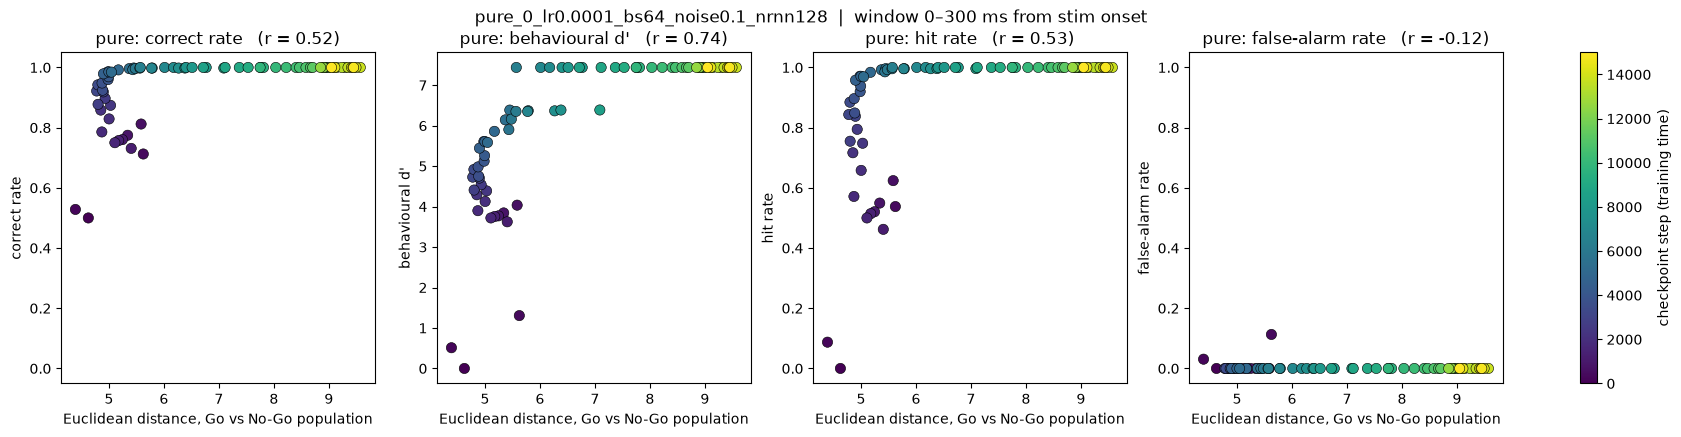

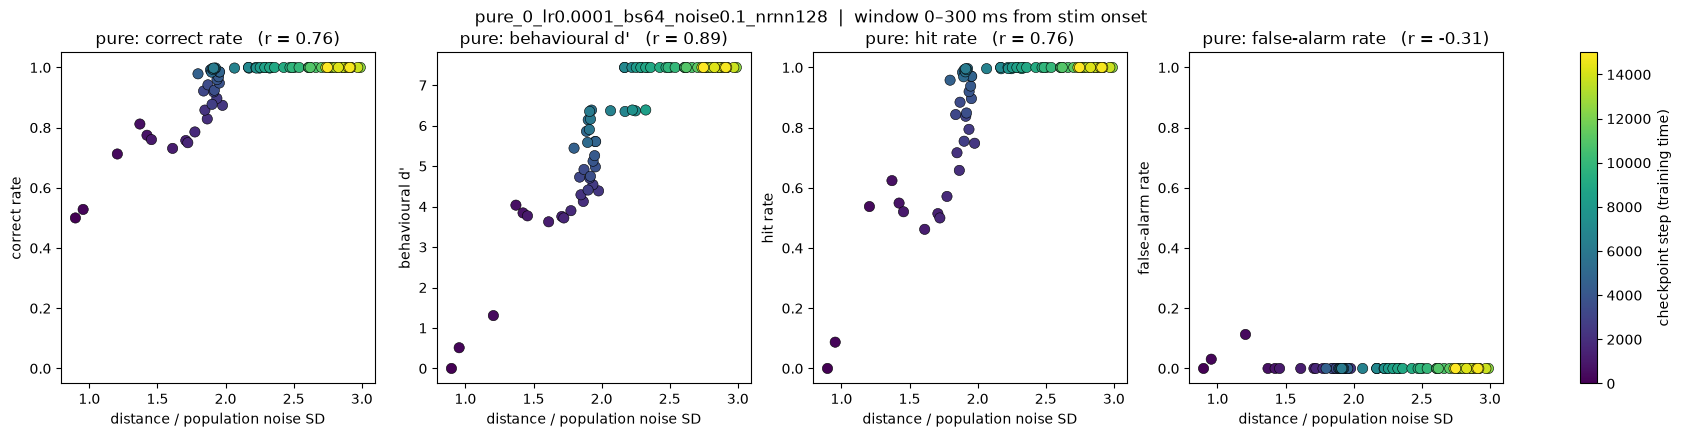

harmonic_0_lr0.0001_bs64_noise0.1_nrnn128: tasks=['harmonic']  window=(0, 300) ms -> steps [20, 50)
  step 0: NO checkpoint_init.pkl in C:\Users\zhixi\Documents\data\results\tone_generalize\harmonic\harmonic_0_lr0.0001_bs64_noise0.1_nrnn128 -> using a random network built from its config.json
  step      0 harmonic  hit=0.00 fa=0.00 correct=0.50 d'=0.00 dist=5.931 noise_sd=5.424 dist/noise=1.09 units=69
  step    200 harmonic  hit=0.17 fa=0.04 correct=0.56 d'=0.80 dist=6.310 noise_sd=4.956 dist/noise=1.27 units=56
  step    400 harmonic  hit=0.96 fa=0.00 correct=0.98 d'=5.49 dist=7.832 noise_sd=3.924 dist/noise=2.00 units=58
  step    500 harmonic  hit=0.90 fa=0.00 correct=0.95 d'=4.97 dist=7.052 noise_sd=3.639 dist/noise=1.94 units=57
  step    600 harmonic  hit=0.92 fa=0.00 correct=0.96 d'=5.16 dist=7.140 noise_sd=3.576 dist/noise=2.00 units=59
  step    800 harmonic  hit=0.78 fa=0.00 correct=0.89 d'=4.48 dist=6.593 noise_sd=3.209 dist/noise=2.05 units=61
  step   1000 harmonic  hit=

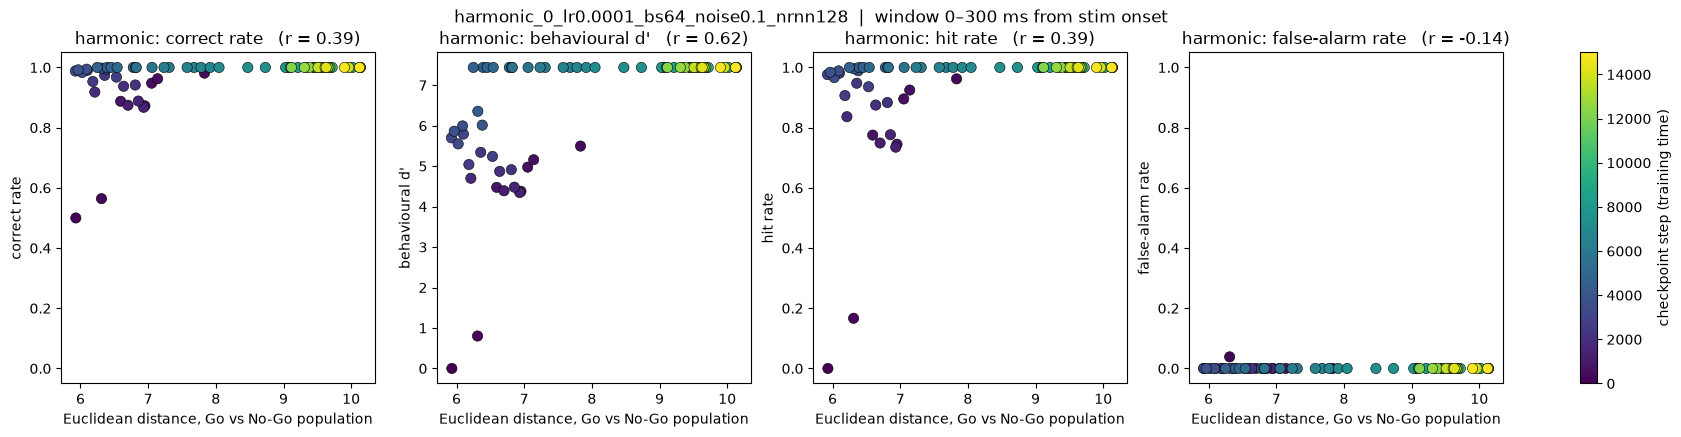

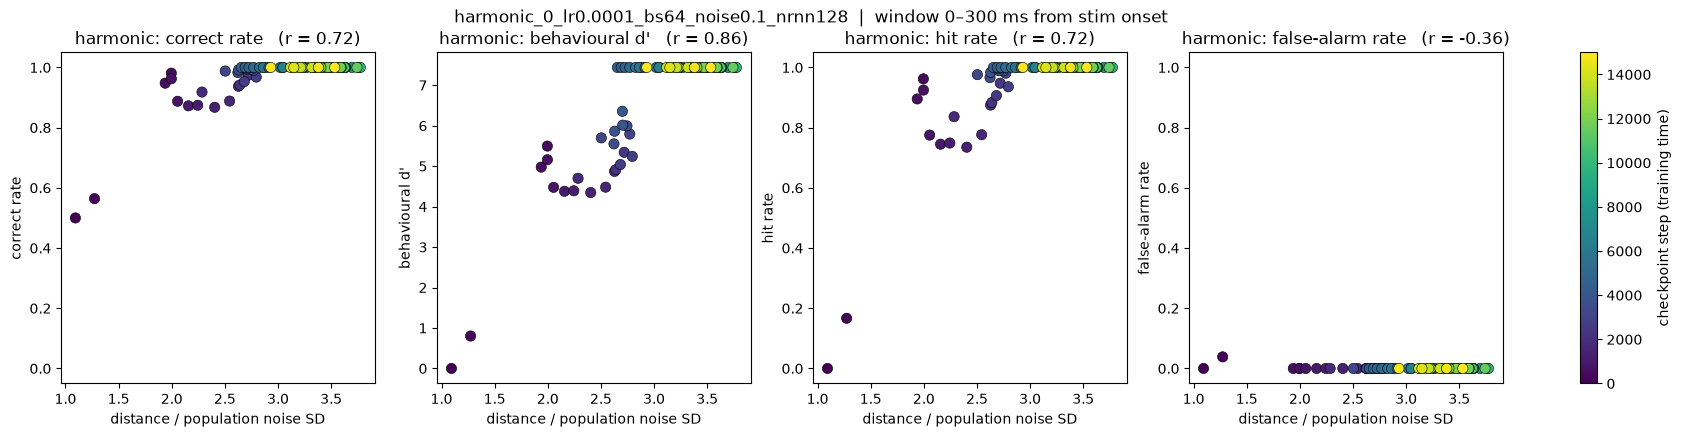

harmonic_0_lr0.0001_bs64_noise0.1_nrnn128_src4000: tasks=['harmonic']  window=(0, 300) ms -> steps [20, 50)
  step 0: using checkpoint_init.pkl  [C:\Users\zhixi\Documents\data\results\tone_generalize\transfer_pure_to_harmonic\all\harmonic\harmonic_0_lr0.0001_bs64_noise0.1_nrnn128_src4000]
  step      0 harmonic  hit=0.93 fa=0.00 correct=0.96 d'=5.19 dist=3.224 noise_sd=2.656 dist/noise=1.21 units=52
  step    200 harmonic  hit=0.94 fa=0.00 correct=0.97 d'=5.31 dist=4.779 noise_sd=2.929 dist/noise=1.63 units=57
  step    400 harmonic  hit=0.92 fa=0.00 correct=0.96 d'=5.15 dist=5.264 noise_sd=2.913 dist/noise=1.81 units=60
  step    600 harmonic  hit=0.97 fa=0.00 correct=0.99 d'=5.64 dist=5.381 noise_sd=2.986 dist/noise=1.80 units=61
  step    800 harmonic  hit=0.96 fa=0.00 correct=0.98 d'=5.48 dist=5.485 noise_sd=2.902 dist/noise=1.89 units=63
  step   1000 harmonic  hit=0.99 fa=0.00 correct=0.99 d'=5.89 dist=5.431 noise_sd=2.879 dist/noise=1.89 units=66
  step   1200 harmonic  hit=0.98

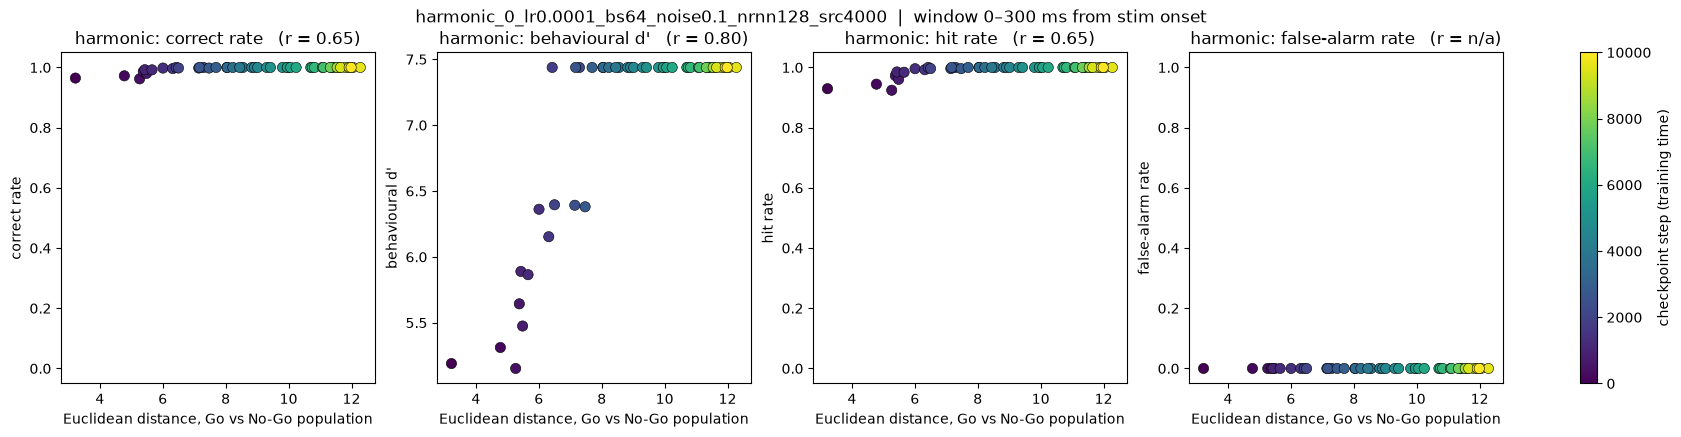

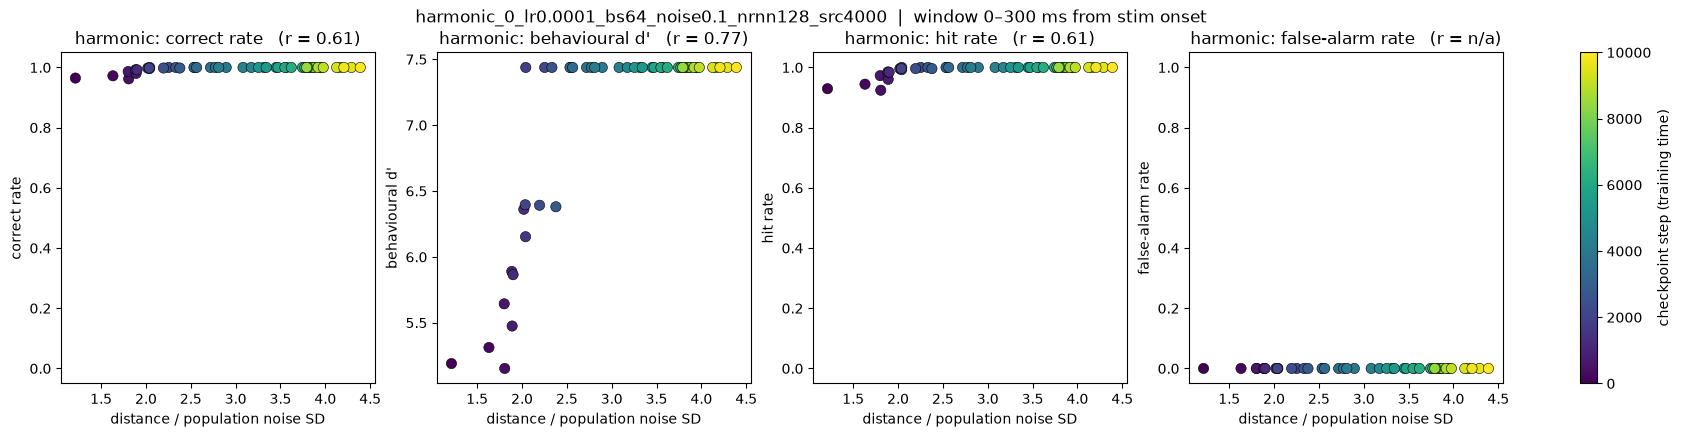

,task,step,hit,fa,correct,behav_dprime,distance,mean_abs_dprime,n_units,noise_var,noise_sd,unit_sd_mean,distance_norm,dprime_axis,label
0,pure,0,0.000000,0.000000,0.500000,0.000000,4.625411,0.747382,62,26.558021,5.153447,0.652776,0.897537,6.829016,PT
1,pure,200,0.087302,0.030769,0.528266,0.512046,4.390317,0.804503,49,21.167777,4.600845,0.655669,0.954241,6.368433,PT
2,pure,400,0.537879,0.112903,0.712488,1.306323,5.624866,1.011963,51,21.773504,4.666209,0.651384,1.205447,4.426111,PT
3,pure,600,0.624031,0.000000,0.812016,4.035101,5.585153,1.231677,51,16.599289,4.074223,0.564995,1.370851,4.684453,PT
4,pure,800,0.549407,0.000000,0.774704,3.843180,5.340286,1.358701,50,14.081257,3.752500,0.519165,1.423128,4.168314,PT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,harmonic,9200,1.000000,0.000000,1.000000,7.438033,11.938816,6.713305,81,8.227036,2.868281,0.241388,4.162359,21.619559,PT-HCT
200,harmonic,9400,1.000000,0.000000,1.000000,7.438033,11.651969,6.567192,80,7.974943,2.823994,0.240375,4.126060,21.135261,PT-HCT
201,harmonic,9600,1.000000,0.000000,1.000000,7.438033,12.279426,6.829817,82,8.191273,2.862040,0.243737,4.290445,21.496121,PT-HCT
202,harmonic,9800,1.000000,0.000000,1.000000,7.438033,11.926881,6.609260,82,8.037144,2.834986,0.240823,4.207034,21.985107,PT-HCT


In [3]:
# reload = True : load previously saved results (no recomputation)
# reload = False: re-simulate behaviour and distances, and save them
all_rows = []
for label, dirs in MODEL_DIRs.items():
    for MODEL_DIR in dirs:
        if reload:
            rows = load_saved_rows(MODEL_DIR, window_ms=WINDOW_MS)
        else:
            rows = discrimination_vs_behavior(MODEL_DIR, window_ms=WINDOW_MS,
                                              n_trials=N_TRIALS, seed=SEED, show=True)
        for row in rows:
            row['label'] = label
        all_rows.extend(rows)
df = pd.DataFrame(all_rows)
df

In [10]:
df.keys()

Index(['task', 'step', 'hit', 'fa', 'correct', 'behav_dprime', 'distance',
       'mean_abs_dprime', 'n_units', 'noise_var', 'noise_sd', 'unit_sd_mean',
       'distance_norm', 'dprime_axis', 'label'],
      dtype='str')

Euclidean distance     vs correct rate    Pearson r =  0.434   p = 8.46e-11   (n = 204)
Euclidean distance     vs behavioural d'  Pearson r =  0.662   p = 4.01e-27   (n = 204)
Euclidean distance     vs hit rate        Pearson r =  0.437   p = 6.45e-11   (n = 204)
Euclidean distance     vs false alarm rate Pearson r = -0.118   p = 0.0939   (n = 204)
population noise SD    vs correct rate    Pearson r = -0.617   p = 7.95e-23   (n = 204)
population noise SD    vs behavioural d'  Pearson r = -0.444   p = 2.88e-11   (n = 204)
population noise SD    vs hit rate        Pearson r = -0.608   p = 4.88e-22   (n = 204)
population noise SD    vs false alarm rate Pearson r =  0.406   p = 1.72e-09   (n = 204)
distance / noise SD    vs correct rate    Pearson r =  0.570   p = 5.98e-19   (n = 204)
distance / noise SD    vs behavioural d'  Pearson r =  0.732   p = 1.57e-35   (n = 204)
distance / noise SD    vs hit rate        Pearson r =  0.569   p = 6.24e-19   (n = 204)
distance / noise SD    vs false 

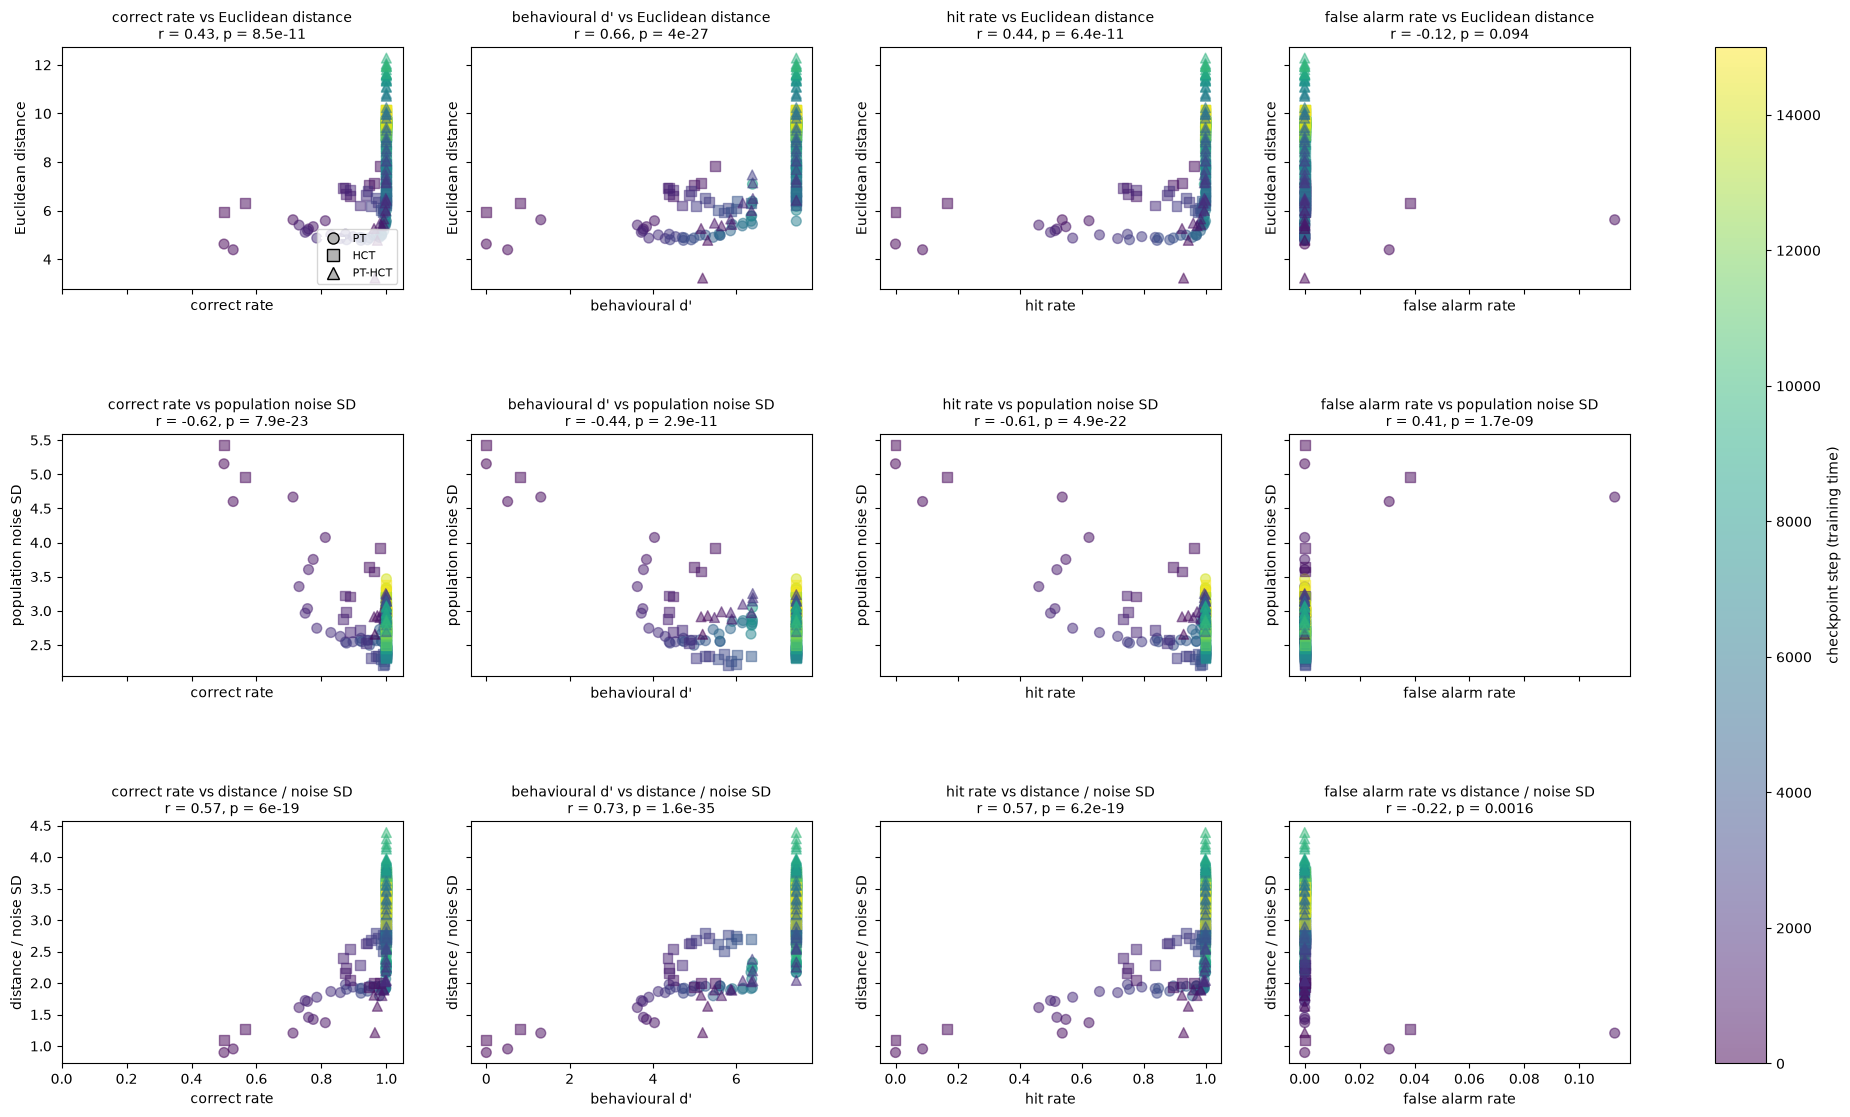

In [16]:
# Neuron metrics (rows) vs behaviour metrics (columns).
#   rows    : Euclidean distance / sqrt(N) | population noise SD / sqrt(N) | distance / noise SD
#   columns : correct rate | behavioural d'  (d' = Z(hit) - Z(FA) does not saturate at 1)
#   colour  : checkpoint step (training time);  marker shape: model (MODEL_DIRs key)
from matplotlib.lines import Line2D

measures = [('distance_per_unit', 'Euclidean distance / sqrt(N units)'),
            ('noise_sd_per_unit', 'population noise SD / sqrt(N units)'),
            ('distance_norm', 'distance / noise SD')]
behaviors = [('correct',      'correct rate'),
             ('behav_dprime', "behavioural d'"),
             ('hit', 'hit rate'),
             ('fa', 'false alarm rate'),
             ]
missing = [k for k in [m[0] for m in measures] + [b[0] for b in behaviors] if k not in df.columns]
assert not missing, f'columns {missing} missing: recompute with reload = False'

labels = list(df['label'].unique())
marker_of = dict(zip(labels, ['o', 's', '^', 'D', 'v', 'P', 'X', '*']))
distance_cutoff = [-0.01, 50]
g_filtered = df[df['distance'].between(distance_cutoff[0], distance_cutoff[1])]
norm = plt.Normalize(g_filtered['step'].min(), g_filtered['step'].max())

fig, axes = plt.subplots(len(measures), len(behaviors),
                         figsize=(5.2 * len(behaviors) + 1.2, 4.4 * len(measures)), squeeze=False, gridspec_kw={'hspace': 0.6}, sharex='col', sharey='row')
for i, (key, name) in enumerate(measures):
    for j, (bkey, bname) in enumerate(behaviors):
        ax = axes[i, j]
        for lab in labels:
            g = g_filtered[g_filtered['label'] == lab]
            sc = ax.scatter(g[bkey], g[key], c=g['step'], cmap='viridis', norm=norm,
                            marker=marker_of[lab], s=50, edgecolor=None, alpha=0.5)
        ax.set(xlabel=bname, ylabel=name)
        if bkey == 'correct':
            ax.set_xlim(0, 1.05)
        # Pearson correlation (all models pooled)
        ok = g_filtered[[bkey, key]].replace([np.inf, -np.inf], np.nan).dropna()
        corr, pval = pearsonr(ok[bkey], ok[key])
        print(f'{name:22s} vs {bname:15s} Pearson r = {corr:6.3f}   p = {pval:.3g}   (n = {len(ok)})')
        ax.set_title(f'{bname} vs {name}\nr = {corr:.2f}, p = {pval:.2g}', fontsize=10)
axes[0, 0].legend(handles=[Line2D([], [], marker=marker_of[l], color='w', markerfacecolor='0.7',
                                  markeredgecolor='k', markersize=8, label=l) for l in labels],
                  loc='lower right', fontsize=8)
fig.colorbar(sc, ax=axes, label='checkpoint step (training time)', fraction=0.03)
plt.show()

Euclidean distance     vs correct rate     Pearson r =  0.434   p = 8.46e-11   (n = 204)
Euclidean distance     vs behavioural d'   Pearson r =  0.662   p = 4.01e-27   (n = 204)
Euclidean distance     vs hit rate         Pearson r =  0.437   p = 6.45e-11   (n = 204)
Euclidean distance     vs false alarm rate Pearson r = -0.118   p = 0.0939   (n = 204)
population noise SD    vs correct rate     Pearson r = -0.617   p = 7.95e-23   (n = 204)
population noise SD    vs behavioural d'   Pearson r = -0.444   p = 2.88e-11   (n = 204)
population noise SD    vs hit rate         Pearson r = -0.608   p = 4.88e-22   (n = 204)
population noise SD    vs false alarm rate Pearson r =  0.406   p = 1.72e-09   (n = 204)
distance / noise SD    vs correct rate     Pearson r =  0.570   p = 5.98e-19   (n = 204)
distance / noise SD    vs behavioural d'   Pearson r =  0.732   p = 1.57e-35   (n = 204)
distance / noise SD    vs hit rate         Pearson r =  0.569   p = 6.24e-19   (n = 204)
distance / noise SD    

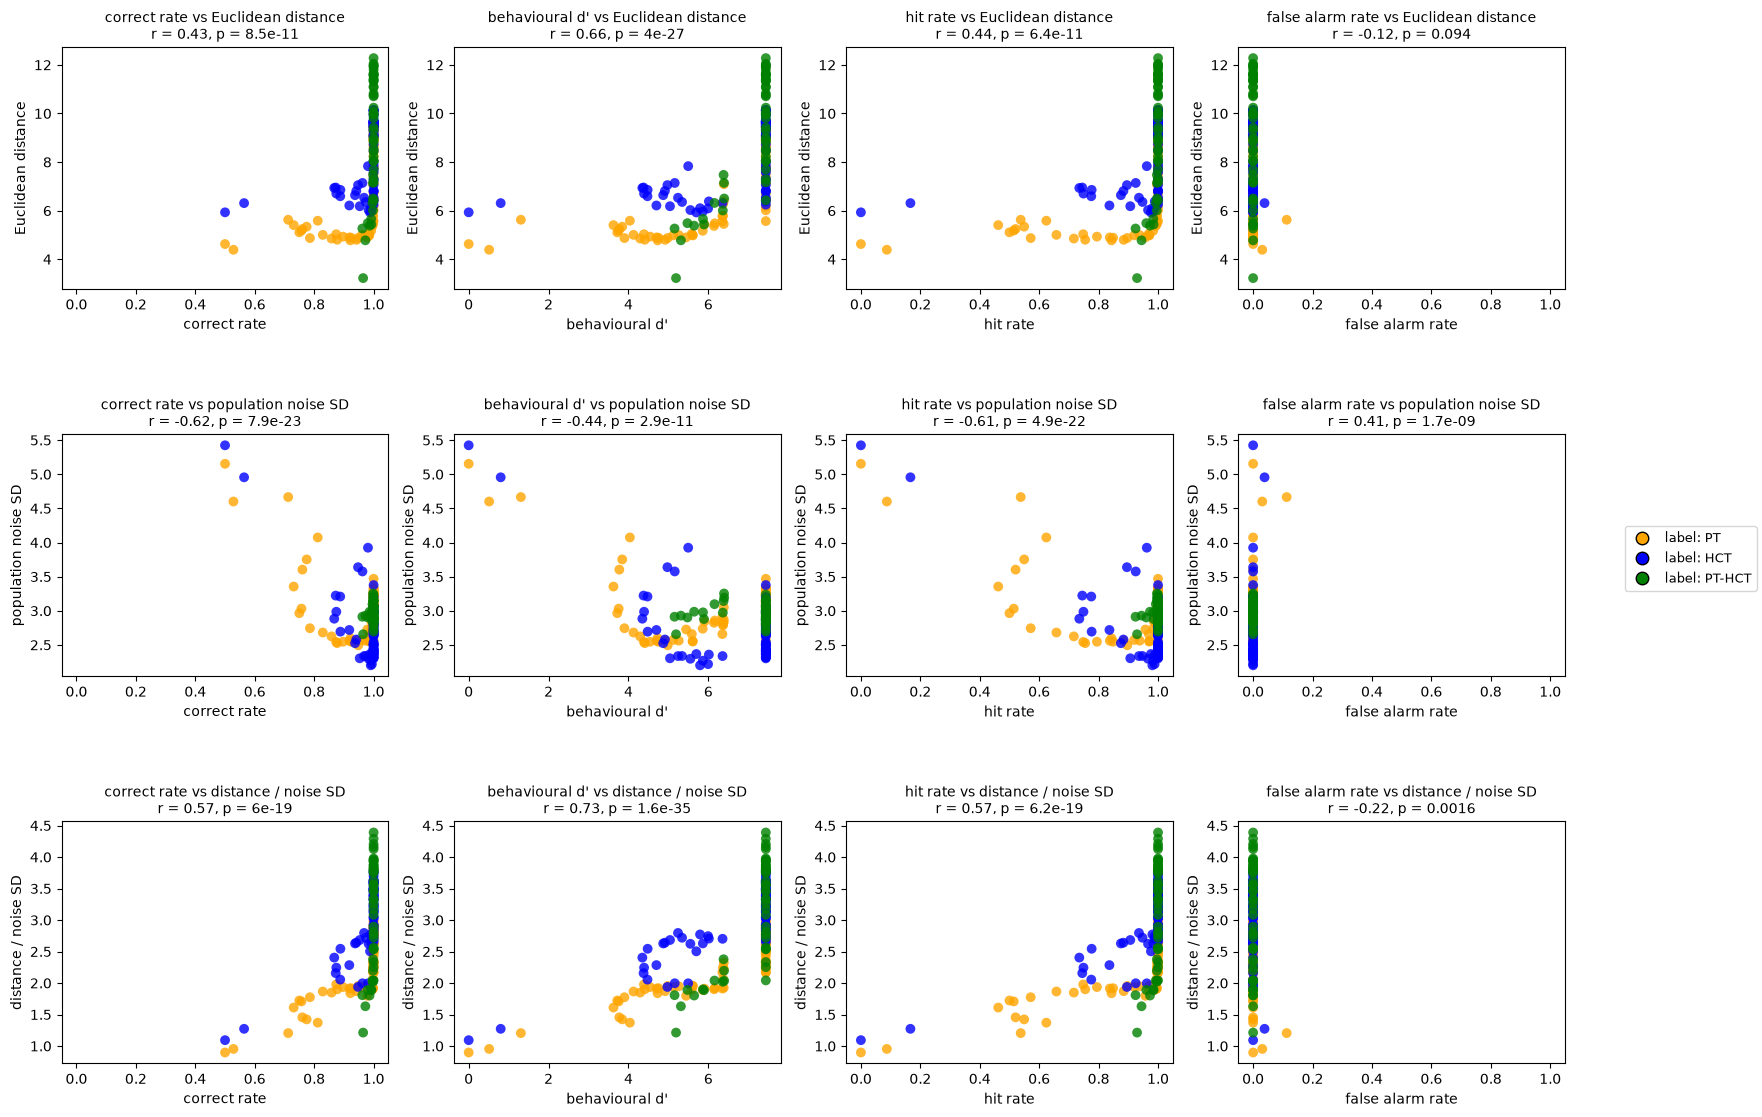

In [36]:
# Neuron metrics (rows) vs behaviour metrics (columns).
#   rows    : Euclidean distance / sqrt(N) | population noise SD / sqrt(N) | distance / noise SD
#   columns : correct rate | behavioural d' | hit rate | false-alarm rate
#             (d' = Z(hit) - Z(FA) does not saturate at 1)
#   colour  : task type (pure / harmonic);  marker shape: model (MODEL_DIRs key)
from matplotlib.lines import Line2D

measures = [('distance_per_unit', 'Euclidean distance / sqrt(N units)'),
            ('noise_sd_per_unit', 'population noise SD / sqrt(N units)'),
            ('distance_norm', 'distance / noise SD')]
behaviors = [('correct',      'correct rate'),
             ('behav_dprime', "behavioural d'"),
             ('hit',          'hit rate'),
             ('fa',           'false alarm rate'),
             ]
RATES = ('correct', 'hit', 'fa')        # behaviour columns that live in [0, 1]
missing = [k for k in [m[0] for m in measures] + [b[0] for b in behaviors] if k not in df.columns]
assert not missing, f'columns {missing} missing: recompute with reload = False'

labels = list(df['label'].unique())     # models  -> marker shape
tasks  = list(df['task'].unique())      # tasks   -> colour (keyed by df['task'], not by model label)
marker_of  = dict(zip(labels, ['o', 's', '^', 'D', 'v', 'P', 'X', '*']))
labels_color = {'PT': 'orange',
                'HCT': 'b',
                'PT-HCT': 'g'
}
distance_cutoff = [-0.01, 50]
g_filtered = df[df['distance'].between(distance_cutoff[0], distance_cutoff[1])]

fig, axes = plt.subplots(len(measures), len(behaviors),
                         figsize=(4.6 * len(behaviors) + 1.0, 4.4 * len(measures)),
                         squeeze=False, gridspec_kw={'hspace': 0.6})
for i, (key, name) in enumerate(measures):
    for j, (bkey, bname) in enumerate(behaviors):
        ax = axes[i, j]
        for lab in labels:
            g = g_filtered[g_filtered['label'] == lab]
            if len(g) == 0:
                continue
            ax.scatter(g[bkey], g[key], c=np.array([labels_color[l] for l in g['label']]),
                       s=50, edgecolor='none', linewidths=0.4, alpha=0.8)
        ax.set(xlabel=bname, ylabel=name)
        if bkey in RATES:
            ax.set_xlim(-0.05, 1.05)
        # Pearson correlation (all models and tasks pooled)
        ok = g_filtered[[bkey, key]].replace([np.inf, -np.inf], np.nan).dropna()
        corr, pval = pearsonr(ok[bkey], ok[key])
        print(f'{name:22s} vs {bname:16s} Pearson r = {corr:6.3f}   p = {pval:.3g}   (n = {len(ok)})')
        ax.set_title(f'{bname} vs {name}\nr = {corr:.2f}, p = {pval:.2g}', fontsize=10)

# one legend for both encodings: colour = model
handles = ([Line2D([], [], marker='o', color='w', markerfacecolor=labels_color[l], markeredgecolor='k',
                   markersize=9, label=f'label: {l}') for l in labels])
fig.legend(handles=handles, loc='center right', fontsize=9)
fig.subplots_adjust(right=0.9)
plt.show()

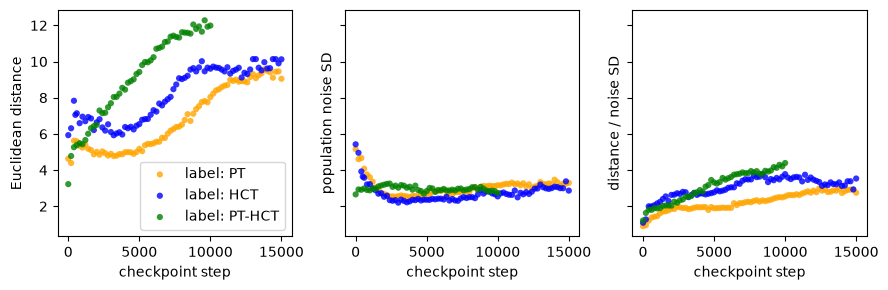

In [37]:
# plot all neuron metrics against checkpoint training steps
# each measurment perplot, when multiple models color coded
fig, axes = plt.subplots(1, len(measures), figsize=(3 * len(measures), 3), squeeze=False, sharey=True)
for i, (key, name) in enumerate(measures):
    ax = axes[0, i]
    for lab in labels:
        g = df[df['label'] == lab]
        if len(g) == 0:
            continue
        ax.scatter(g['step'], g[key], c=np.array([labels_color[l] for l in g['label']]),
                   s=20, edgecolor='none', linewidths=0.4, alpha=0.8, label=f'label: {lab}')
    ax.set(xlabel='checkpoint step', ylabel=name)
axes[0, 0].legend()
plt.tight_layout()

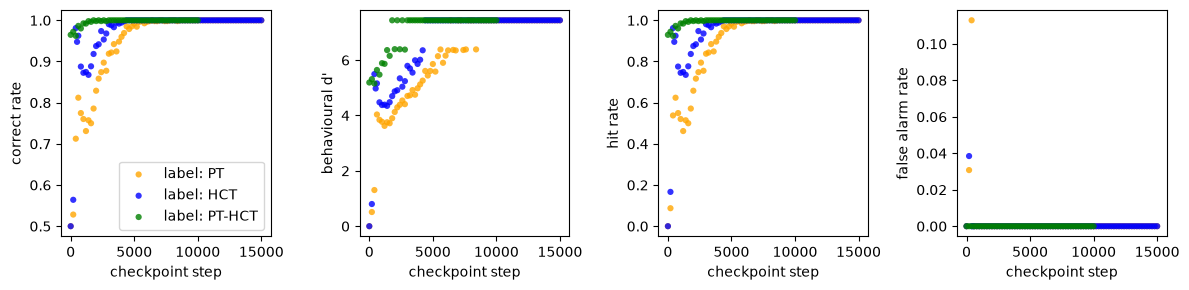

In [39]:
# same cell as previous one, but for behavior metrics vs checkpoint training steps
fig, axes = plt.subplots(1, len(behaviors), figsize=(3 * len(behaviors), 3), squeeze=False, sharey=False)
for i, (bkey, bname) in enumerate(behaviors):
    ax = axes[0, i]
    for lab in labels:
        g = df[df['label'] == lab]
        if len(g) == 0:
            continue
        ax.scatter(g['step'], g[bkey], c=np.array([labels_color[l] for l in g['label']]),
                   s=20, edgecolor='none', linewidths=0.4, alpha=0.8, label=f'label: {lab}')
    ax.set(xlabel='checkpoint step', ylabel=bname)
axes[0, 0].legend()
plt.tight_layout()
